In [ ]:
!pip install -q --no-cache-dir copernicusmarine cdsapi opendrift

In [1]:
import os, glob, zipfile
import xml.etree.ElementTree as ET
from pathlib import Path
from datetime import timedelta

import numpy as np, scipy, skimage, torch, rasterio, requests
import xarray as xr, pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import RegularGridInterpolator
import copernicusmarine, cdsapi

print("NumPy:", np.__version__, "| SciPy:", scipy.__version__, "| Rasterio:", rasterio.__version__)

NumPy: 2.5.2 | SciPy: 1.16.3 | Rasterio: 1.5.0


In [2]:
from kaggle_secrets import UserSecretsClient
secrets = UserSecretsClient()

CMEMS_USER    = secrets.get_secret("CMEMS_USER")
CMEMS_PASS    = secrets.get_secret("CMEMS_PASS")
CDSAPI_URL    = secrets.get_secret("CDSAPI_URL")
CDSAPI_KEY    = secrets.get_secret("CDSAPI_KEY")
GFW_API_KEY   = secrets.get_secret("GFW_API_KEY")
CDSE_USERNAME = secrets.get_secret("CDSE_USERNAME")
CDSE_PASSWORD = secrets.get_secret("CDSE_PASSWORD")

os.environ["COPERNICUSMARINE_SERVICE_USERNAME"] = CMEMS_USER
os.environ["COPERNICUSMARINE_SERVICE_PASSWORD"] = CMEMS_PASS
print("secrets loaded")

secrets loaded


In [3]:
ok = copernicusmarine.login(username=CMEMS_USER, password=CMEMS_PASS, check_credentials_valid=True)
print("CMEMS login:", ok)

INFO - 2026-09-02T13:41:00Z - Checking if credentials are valid.
INFO - 2026-09-02T13:41:01Z - Valid credentials from input username and password.


CMEMS login: True


In [25]:
# CELL 6 — HOURLY CMEMS OCEAN CURRENTS
# Required for the 6-hour backward hindcast

CMEMS_DIR = f"{WORK_DIR}/cmems"
os.makedirs(CMEMS_DIR, exist_ok=True)

CMEMS_FILE = f"{CMEMS_DIR}/currents_hourly.nc"

copernicusmarine.subset(
    dataset_id="cmems_mod_glo_phy_anfc_merged-uv_PT1H-i",
    variables=["uo", "vo"],
    minimum_longitude=AOI["lon_min"],
    maximum_longitude=AOI["lon_max"],
    minimum_latitude=AOI["lat_min"],
    maximum_latitude=AOI["lat_max"],
    start_datetime=f"{DEMO_DATE}T06:00:00",
    end_datetime=f"{DEMO_DATE}T12:00:00",
    minimum_depth=0,
    maximum_depth=1,
    output_directory=CMEMS_DIR,
    output_filename="currents_hourly.nc",
    username=CMEMS_USER,
    password=CMEMS_PASS,
)

print("Hourly CMEMS currents downloaded:")
print(CMEMS_FILE)

INFO - 2026-09-02T14:39:39Z - Selected dataset version: "202211"
14:39:39 INFO    copernicusmarine:255: Selected dataset version: "202211"
INFO - 2026-09-02T14:39:39Z - Selected dataset part: "default"
14:39:39 INFO    copernicusmarine:277: Selected dataset part: "default"
WARNING - 2026-09-02T14:39:39Z - Some of your subset selection [0.0, 1.0] for the depth dimension exceed the dataset coordinates [0.49402499198913574, 0.49402499198913574]
14:39:39 WARNING copernicusmarine:818: Some of your subset selection [0.0, 1.0] for the depth dimension exceed the dataset coordinates [0.49402499198913574, 0.49402499198913574]
INFO - 2026-09-02T14:39:43Z - Total size of the download: 22.56 KB.
14:39:43 INFO    copernicusmarine:53: Total size of the download: 22.56 KB.


Hourly CMEMS currents downloaded:
/kaggle/working/cmems/currents_hourly.nc


In [26]:
#temporary
# TEMPORARY QC — DELETE LATER

ds_cmems = xr.open_dataset(CMEMS_FILE)

print(ds_cmems)
print("\nTime:")
print(ds_cmems.time.values)

print("\nuo range:",
      float(ds_cmems["uo"].min()),
      float(ds_cmems["uo"].max()))

print("vo range:",
      float(ds_cmems["vo"].min()),
      float(ds_cmems["vo"].max()))

<xarray.Dataset> Size: 10kB
Dimensions:    (time: 7, depth: 1, latitude: 13, longitude: 13)
Coordinates:
  * time       (time) datetime64[ns] 56B 2026-08-01T06:00:00 ... 2026-08-01T1...
  * depth      (depth) float32 4B 0.494
  * latitude   (latitude) float32 52B 18.0 18.08 18.17 ... 18.83 18.92 19.0
  * longitude  (longitude) float32 52B 72.0 72.08 72.17 ... 72.83 72.92 73.0
Data variables:
    uo         (time, depth, latitude, longitude) float32 5kB ...
    vo         (time, depth, latitude, longitude) float32 5kB ...
Attributes: (12/13)
    Conventions:                   CF-1.6
    area:                          GLOBAL
    contact:                       servicedesk.cmems@mercator-ocean.eu
    credit:                        E.U. Copernicus Marine Service Information...
    institution:                   MERCATOR OCEAN
    licence:                       http://marine.copernicus.eu/services-portf...
    ...                            ...
    product_user_manual:           http://marin

In [7]:
ERA5_FILE = f"{WORK_DIR}/era5_wind_24h.nc"
cds_client = cdsapi.Client(url=CDSAPI_URL, key=CDSAPI_KEY)
cds_client.retrieve(
    "reanalysis-era5-single-levels",
    {
        "product_type": "reanalysis",
        "variable": ["10m_u_component_of_wind", "10m_v_component_of_wind"],
        "year": DEMO_DATE[:4], "month": DEMO_DATE[5:7], "day": DEMO_DATE[8:10],
        "time": [f"{h:02d}:00" for h in range(24)],
        "area": [AOI["lat_max"], AOI["lon_min"], AOI["lat_min"], AOI["lon_max"]],
        "data_format": "netcdf",
    },
    ERA5_FILE,
)
print("ERA5 downloaded:", ERA5_FILE)

2026-09-02 13:41:52,684 INFO Request ID is 7f123f1b-54ef-4b8f-9f4c-227dd093d41a
2026-09-02 13:41:52,873 INFO status has been updated to accepted
2026-09-02 13:42:46,979 INFO status has been updated to successful


60c1e30c47e7d778918923602d2f0a7e.nc:   0%|          | 0.00/34.8k [00:00<?, ?B/s]

ERA5 downloaded: /kaggle/working/era5_wind_24h.nc


In [15]:
ds_cmems = xr.open_dataset(CMEMS_FILE)
ds_era5  = xr.open_dataset(ERA5_FILE)
print("uo/vo range:", float(ds_cmems["uo"].min()), float(ds_cmems["uo"].max()))
print("u10/v10 range:", float(ds_era5["u10"].min()), float(ds_era5["u10"].max()))
print("ERA5 time:", ds_era5.valid_time.values[0], "to", ds_era5.valid_time.values[-1])

uo/vo range: -0.04952046275138855 0.1301649957895279
u10/v10 range: 4.6268310546875 12.441131591796875
ERA5 time: 2026-08-01T00:00:00.000000000 to 2026-08-01T23:00:00.000000000


In [16]:
GFW_URL = "https://gateway.api.globalfishingwatch.org"
headers = {"Authorization": f"Bearer {GFW_API_KEY}"}
params = {"query": "7831410", "datasets[0]": "public-global-vessel-identity:latest"}
response = requests.get(f"{GFW_URL}/v3/vessels/search", headers=headers, params=params, timeout=30)
print("HTTP status:", response.status_code)
print(response.text[:500] if response.ok else "failed: " + response.text[:500])

HTTP status: 200
{"limit":30,"since":null,"total":1,"entries":[{"dataset":"public-global-vessel-identity:v4.0","registryInfoTotalRecords":1,"registryInfo":[{"id":"72f191cf1cb981cefc7733d32abba37e","sourceCode":["IMO","SNP","TMT_OTHER"],"ssvid":"701000948","flag":"ARG","shipname":"CLAUDINA","nShipname":"CLAUDINA","callsign":"LW3058","imo":"7831410","latestVesselInfo":true,"transmissionDateFrom":"2012-01-03T07:29:51Z","transmissionDateTo":"2023-04-13T14:15:39Z","geartypes":["FISHING"],"lengthM":54.4,"tonnageGt":36


In [27]:
reader_cmems = reader_netCDF_CF_generic.Reader(CMEMS_FILE)
reader_era5  = reader_netCDF_CF_generic.Reader(ERA5_FILE)

print("CMEMS coverage:", reader_cmems.start_time, "to", reader_cmems.end_time)
print("ERA5 coverage:", reader_era5.start_time, "to", reader_era5.end_time)

14:42:32 INFO    opendrift.readers:67: Opening file with xr.open_dataset
14:42:32 INFO    opendrift.readers.reader_netCDF_CF_generic:307: Grid coordinates are detected, but proj4 string not given: assuming latlong
14:42:32 INFO    opendrift.readers.reader_netCDF_CF_generic:340: Detected dimensions: {'z': 'depth', 'y': 'latitude', 'x': 'longitude', 'time': 'time'}
14:42:32 INFO    opendrift.readers.basereader:175: Variable x_sea_water_velocity will be rotated from eastward_sea_water_velocity
14:42:32 INFO    opendrift.readers.basereader:175: Variable y_sea_water_velocity will be rotated from northward_sea_water_velocity
14:42:32 INFO    opendrift.readers:67: Opening file with xr.open_dataset
14:42:32 INFO    opendrift.readers.reader_netCDF_CF_generic:340: Detected dimensions: {'time': 'valid_time', 'x': 'longitude', 'y': 'latitude'}
14:42:32 INFO    opendrift.readers.basereader:175: Variable x_wind will be rotated from eastward_wind
14:42:32 INFO    opendrift.readers.basereader:175: Var

CMEMS coverage: 2026-08-01 06:00:00 to 2026-08-01 12:00:00
ERA5 coverage: 2026-08-01 00:00:00 to 2026-08-01 23:00:00


In [19]:
#TEMPORARY, delete later
print("CMEMS:")
print("  time:", reader_cmems.start_time, "to", reader_cmems.end_time)
print("  variables:", reader_cmems.variables)

print("\nERA5:")
print("  time:", reader_era5.start_time, "to", reader_era5.end_time)
print("  variables:", reader_era5.variables)

CMEMS:
  time: 2026-08-01 00:00:00 to 2026-08-01 00:00:00
  variables: ['eastward_sea_water_velocity', 'northward_sea_water_velocity', 'x_sea_water_velocity', 'y_sea_water_velocity', 'sea_water_speed']

ERA5:
  time: 2026-08-01 00:00:00 to 2026-08-01 23:00:00
  variables: ['eastward_wind', 'northward_wind', 'x_wind', 'y_wind', 'wind_speed']


In [31]:
# CELL 12 — RUN BACKWARD HINDCAST

HOURS_BACK = 6

hindcast = run_backward_hindcast(
    lon=SLICK_LON,
    lat=SLICK_LAT,
    time=SLICK_TIME,
    hours_back=HOURS_BACK
)

print("Hindcast completed")
print(hindcast.result)

14:46:30 INFO    opendrift:569: OpenDriftSimulation initialised (version 1.14.11)
14:46:30 INFO    opendrift.models.basemodel.environment:203: Adding a global landmask from GSHHG
14:46:30 INFO    opendrift.models.basemodel.environment:227: Fallback values will be used for the following variables which have no readers: 
14:46:30 INFO    opendrift.models.basemodel.environment:230: 	sea_surface_height: 0.000000
14:46:30 INFO    opendrift.models.basemodel.environment:230: 	upward_sea_water_velocity: 0.000000
14:46:30 INFO    opendrift.models.basemodel.environment:230: 	ocean_vertical_diffusivity: 0.000000
14:46:30 INFO    opendrift.models.basemodel.environment:230: 	sea_surface_wave_significant_height: 0.000000
14:46:30 INFO    opendrift.models.basemodel.environment:230: 	sea_surface_wave_stokes_drift_x_velocity: 0.000000
14:46:30 INFO    opendrift.models.basemodel.environment:230: 	sea_surface_wave_stokes_drift_y_velocity: 0.000000
14:46:30 INFO    opendrift.models.basemodel.environment:2

Hindcast completed
<xarray.Dataset> Size: 62kB
Dimensions:                                   (trajectory: 100, time: 7)
Coordinates:
  * trajectory                                (trajectory) int64 800B 0 1 ... 99
  * time                                      (time) datetime64[ns] 56B 2026-...
Data variables: (12/22)
    status                                    (trajectory, time) float32 3kB ...
    moving                                    (trajectory, time) float32 3kB ...
    age_seconds                               (trajectory, time) float32 3kB ...
    origin_marker                             (trajectory, time) float32 3kB ...
    lon                                       (trajectory, time) float32 3kB ...
    lat                                       (trajectory, time) float32 3kB ...
    ...                                        ...
    horizontal_diffusivity                    (trajectory, time) float32 3kB ...
    sea_surface_wave_significant_height       (trajectory, time

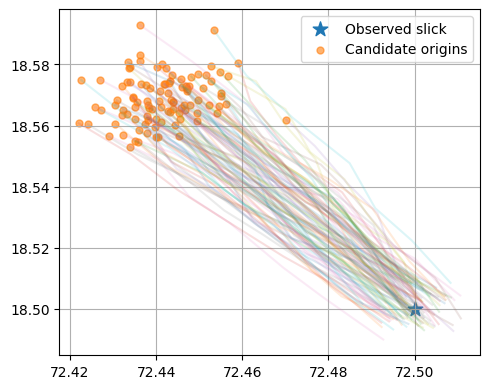

Saved: /kaggle/working/candidate_origins.csv


In [32]:
# CELL 13 — PLOT AND SAVE CANDIDATE ORIGINS

lon = hindcast.result["lon"].values
lat = hindcast.result["lat"].values

origin_lon = lon[:, -1]
origin_lat = lat[:, -1]

plt.figure(figsize=(5, 4))

for i in range(lon.shape[0]):
    plt.plot(lon[i, :], lat[i, :], alpha=0.15)

plt.scatter(
    SLICK_LON, SLICK_LAT,
    s=120, marker="*",
    label="Observed slick"
)

plt.scatter(
    origin_lon, origin_lat,
    s=25, alpha=0.6,
    label="Candidate origins"
)

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

pd.DataFrame({
    "lon": origin_lon,
    "lat": origin_lat
}).to_csv(
    f"{WORK_DIR}/candidate_origins.csv",
    index=False
)

print("Saved:", f"{WORK_DIR}/candidate_origins.csv")

In [30]:
# TEMPORARY QC — DELETE LATER

print("Hindcast currents actually stored:")

for v in ["x_sea_water_velocity", "y_sea_water_velocity"]:
    if v in hindcast.result:
        vals = hindcast.result[v].values
        print(v, "range:", np.nanmin(vals), "to", np.nanmax(vals))
    else:
        print(v, "NOT FOUND")

Hindcast currents actually stored:
x_sea_water_velocity range: 0.062176343 to 0.07947502
y_sea_water_velocity range: -0.37199885 to -0.339143


In [21]:
#temp
print("Hindcast time:")
print(hindcast.result.time.values)

print("\nSample particle position:")
print("Start:", hindcast.result.lon.values[0, 0],
      hindcast.result.lat.values[0, 0])
print("End:  ", hindcast.result.lon.values[0, -1],
      hindcast.result.lat.values[0, -1])

print("\nEnvironment variables:")
for v in ["eastward_sea_water_velocity",
          "northward_sea_water_velocity",
          "eastward_wind",
          "northward_wind"]:
    if v in hindcast.result:
        vals = hindcast.result[v].values
        print(v, "range:", np.nanmin(vals), "to", np.nanmax(vals))

Hindcast time:
['2026-08-01T12:00:00.000000000' '2026-08-01T11:00:00.000000000'
 '2026-08-01T10:00:00.000000000' '2026-08-01T09:00:00.000000000'
 '2026-08-01T08:00:00.000000000' '2026-08-01T07:00:00.000000000'
 '2026-08-01T06:00:00.000000000']

Sample particle position:
Start: 72.5019 18.506037
End:   72.45732 18.504305

Environment variables:


In [33]:
# CELL 15 — COPERNICUS DATA SPACE AUTHENTICATION

CDSE_TOKEN_URL = "https://identity.dataspace.copernicus.eu/auth/realms/CDSE/protocol/openid-connect/token"

token_data = {
    "client_id": "cdse-public",
    "username": CDSE_USERNAME,
    "password": CDSE_PASSWORD,
    "grant_type": "password",
}

response = requests.post(
    CDSE_TOKEN_URL,
    data=token_data,
    timeout=30
)

response.raise_for_status()

CDSE_TOKEN = response.json()["access_token"]

print("CDSE authentication successful")
print("Token obtained:", bool(CDSE_TOKEN))

CDSE authentication successful
Token obtained: True


In [37]:
# CELL 16 — SEARCH SENTINEL-1 GRD SCENES OVER AOI

CATALOGUE_URL = "https://catalogue.dataspace.copernicus.eu/odata/v1/Products"

# Build AOI polygon
aoi_polygon = (
    f"POLYGON(("
    f"{AOI['lon_min']} {AOI['lat_min']},"
    f"{AOI['lon_max']} {AOI['lat_min']},"
    f"{AOI['lon_max']} {AOI['lat_max']},"
    f"{AOI['lon_min']} {AOI['lat_max']},"
    f"{AOI['lon_min']} {AOI['lat_min']}"
    f"))"
)

start_time = f"{DEMO_DATE}T00:00:00.000Z"
end_time   = f"{DEMO_DATE}T23:59:59.999Z"

spatial_filter = (
    f"OData.CSC.Intersects("
    f"area=geography'SRID=4326;{aoi_polygon}')"
)

odata_filter = (
    "Collection/Name eq 'SENTINEL-1' "
    "and contains(Name,'IW_GRDH') "
    f"and {spatial_filter} "
    f"and ContentDate/Start ge {start_time} "
    f"and ContentDate/Start le {end_time}"
)

params = {
    "$filter": odata_filter,
    "$top": 100,
    "$orderby": "ContentDate/Start asc",
}

headers = {
    "Authorization": f"Bearer {CDSE_TOKEN}"
}

response = requests.get(
    CATALOGUE_URL,
    params=params,
    headers=headers,
    timeout=60
)

response.raise_for_status()

products = response.json()["value"]

print("Sentinel-1 GRD scenes intersecting AOI:", len(products))

for i, p in enumerate(products):
    print(
        f"\n[{i}] {p['Name']}"
        f"\n    ID: {p['Id']}"
        f"\n    Start: {p['ContentDate']['Start']}"
    )

Sentinel-1 GRD scenes intersecting AOI: 2

[0] S1D_IW_GRDH_1SDV_20260801T010236_20260801T010307_003925_0071AB_69F6.SAFE
    ID: 96427508-4f39-41bf-96bf-c7ec14309e49
    Start: 2026-08-01T01:02:36.478872Z

[1] S1D_IW_GRDH_1SDV_20260801T010236_20260801T010307_003925_0071AB_E37D_COG.SAFE
    ID: f2407cd1-0f5f-411f-a968-ee1faefaba0c
    Start: 2026-08-01T01:02:36.478872Z


In [38]:
# CELL 17 — SELECT SENTINEL-1 SCENE

# Prefer the COG version
cog_products = [
    p for p in products
    if "_COG.SAFE" in p["Name"]
]

if not cog_products:
    raise RuntimeError("COG Sentinel-1 product not found.")

selected_product = cog_products[0]

S1_ID = selected_product["Id"]
S1_NAME = selected_product["Name"]

print("Selected Sentinel-1 scene:")
print("Name:", S1_NAME)
print("ID:", S1_ID)
print("Start:", selected_product["ContentDate"]["Start"])

Selected Sentinel-1 scene:
Name: S1D_IW_GRDH_1SDV_20260801T010236_20260801T010307_003925_0071AB_E37D_COG.SAFE
ID: f2407cd1-0f5f-411f-a968-ee1faefaba0c
Start: 2026-08-01T01:02:36.478872Z


In [39]:
# CELL 18 — DOWNLOAD SELECTED SENTINEL-1 PRODUCT

DOWNLOAD_DIR = f"{WORK_DIR}/sentinel1"
os.makedirs(DOWNLOAD_DIR, exist_ok=True)

DOWNLOAD_URL = (
    f"https://download.dataspace.copernicus.eu/odata/v1/Products"
    f"({S1_ID})/$value"
)

headers = {
    "Authorization": f"Bearer {CDSE_TOKEN}"
}

response = requests.get(
    DOWNLOAD_URL,
    headers=headers,
    stream=True,
    timeout=120
)

response.raise_for_status()

S1_ZIP = f"{DOWNLOAD_DIR}/{S1_NAME}.zip"

with open(S1_ZIP, "wb") as f:
    for chunk in response.iter_content(chunk_size=1024 * 1024):
        if chunk:
            f.write(chunk)

print("Sentinel-1 product downloaded:")
print(S1_ZIP)
print("Size (MB):", round(os.path.getsize(S1_ZIP) / 1024**2, 2))

Sentinel-1 product downloaded:
/kaggle/working/sentinel1/S1D_IW_GRDH_1SDV_20260801T010236_20260801T010307_003925_0071AB_E37D_COG.SAFE.zip
Size (MB): 1237.41


In [41]:
# CELL 19 — EXTRACT SENTINEL-1 PRODUCT

EXTRACT_DIR = f"{DOWNLOAD_DIR}/extracted"
os.makedirs(EXTRACT_DIR, exist_ok=True)

# Extract only if not already extracted
if not os.listdir(EXTRACT_DIR):
    with zipfile.ZipFile(S1_ZIP, "r") as z:
        z.extractall(EXTRACT_DIR)

print("Sentinel-1 product extracted.")
print("Location:", EXTRACT_DIR)

# Find the extracted SAFE directory
safe_dirs = list(Path(EXTRACT_DIR).glob("*.SAFE"))

if not safe_dirs:
    raise RuntimeError("Extracted SAFE directory not found.")

S1_SAFE = safe_dirs[0]

print("SAFE directory:")
print(S1_SAFE)

Sentinel-1 product extracted.
Location: /kaggle/working/sentinel1/extracted
SAFE directory:
/kaggle/working/sentinel1/extracted/S1D_IW_GRDH_1SDV_20260801T010236_20260801T010307_003925_0071AB_E37D_COG.SAFE


In [42]:
# CELL 20 — INSPECT VV MEASUREMENT AND CALIBRATION

import rasterio

# Find VV measurement TIFF
vv_files = list(S1_SAFE.glob("measurement/*vv*.tiff"))
cal_files = list(S1_SAFE.glob("annotation/calibration/*vv*.xml"))

if not vv_files:
    raise RuntimeError("VV measurement TIFF not found.")

if not cal_files:
    raise RuntimeError("VV calibration XML not found.")

VV_TIFF = vv_files[0]
VV_CAL_XML = cal_files[0]

print("VV measurement:")
print(VV_TIFF)

print("\nVV calibration XML:")
print(VV_CAL_XML)

# Inspect raster metadata
with rasterio.open(VV_TIFF) as src:
    print("\nRaster:")
    print("Width:", src.width)
    print("Height:", src.height)
    print("CRS:", src.crs)
    print("Dtype:", src.dtypes[0])
    print("Bands:", src.count)
    print("Resolution:", src.res)

    sample = src.read(1, out_shape=(1, min(1000, src.height), min(1000, src.width)))

print("\nSample measurement values:")
print("Min:", np.nanmin(sample))
print("Max:", np.nanmax(sample))
print("Mean:", np.nanmean(sample))

14:58:58 WARNING py.warnings:112: /tmp/ipykernel_145/2638517662.py:34: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  sample = src.read(1, out_shape=(1, min(1000, src.height), min(1000, src.width)))



VV measurement:
/kaggle/working/sentinel1/extracted/S1D_IW_GRDH_1SDV_20260801T010236_20260801T010307_003925_0071AB_E37D_COG.SAFE/measurement/s1d-iw-grd-vv-20260801t010236-20260801t010307-003925-0071ab-001-cog.tiff

VV calibration XML:
/kaggle/working/sentinel1/extracted/S1D_IW_GRDH_1SDV_20260801T010236_20260801T010307_003925_0071AB_E37D_COG.SAFE/annotation/calibration/calibration-s1d-iw-grd-vv-20260801t010236-20260801t010307-003925-0071ab-001-cog.xml

Raster:
Width: 25521
Height: 20860
CRS: None
Dtype: uint16
Bands: 1
Resolution: (1.0, 1.0)

Sample measurement values:
Min: 0
Max: 10154
Mean: 179.587914


In [43]:
# CELL 21 — INSPECT VV CALIBRATION LUT

tree = ET.parse(VV_CAL_XML)
root = tree.getroot()

# Find calibration vectors
calibration_vectors = root.findall(".//calibrationVector")

print("Calibration vectors found:", len(calibration_vectors))

if not calibration_vectors:
    raise RuntimeError("No calibration vectors found in VV calibration XML.")

# Inspect the first calibration vector
first = calibration_vectors[0]

print("\nFirst calibration vector:")
print("Line:", first.findtext("line"))
print("Pixel count:", len(first.find("pixel").text.split()))
print("Pixel sample:", first.findtext("pixel").split()[:10])
print("SigmaNought sample:", first.findtext("sigmaNought").split()[:10])

Calibration vectors found: 34

First calibration vector:
Line: 0
Pixel count: 639
Pixel sample: ['0', '40', '80', '120', '160', '200', '240', '280', '320', '360']
SigmaNought sample: ['7.086065e+02', '7.083151e+02', '7.080244e+02', '7.077341e+02', '7.074445e+02', '7.071555e+02', '7.068670e+02', '7.065792e+02', '7.062919e+02', '7.060051e+02']


In [ ]:
# CELL 23 — VISUALIZE CALIBRATED VV σ⁰

plt.figure(figsize=(12, 8))

# Display with robust percentile limits
vmin, vmax = np.nanpercentile(
    sigma0_db,
    [2, 98]
)

plt.imshow(
    sigma0_db,
    cmap="gray",
    vmin=vmin,
    vmax=vmax
)

plt.colorbar(label="VV σ⁰ (dB)")
plt.title("Sentinel-1 VV Backscatter — Calibrated σ⁰")
plt.axis("off")
plt.tight_layout()
plt.show()

print("Display range:")
print("2nd percentile:", vmin, "dB")
print("98th percentile:", vmax, "dB")

In [6]:
# MEMORY-SAFE VV CALIBRATION
# Processes Sentinel-1 in chunks instead of loading the full image into RAM.

import rasterio
import xml.etree.ElementTree as ET
import numpy as np

# --- Read calibration LUT ---
tree = ET.parse(VV_CAL_XML)
root = tree.getroot()

calibration_vectors = root.findall(".//calibrationVector")

cal_lines = []
cal_pixels = []
cal_sigma = []

for vector in calibration_vectors:
    cal_lines.append(int(vector.findtext("line")))
    cal_pixels.append(
        np.array(vector.findtext("pixel").split(), dtype=np.float32)
    )
    cal_sigma.append(
        np.array(vector.findtext("sigmaNought").split(), dtype=np.float32)
    )

cal_lines = np.array(cal_lines)
cal_sigma = np.array(cal_sigma)

print("Calibration vectors:", len(cal_lines))

# --- Inspect raster ---
with rasterio.open(VV_TIFF) as src:
    height = src.height
    width = src.width

print("Image:", height, "x", width)
print("Pixels:", height * width)

# --- Choose a manageable chunk size ---
CHUNK_ROWS = 250

print("Processing", CHUNK_ROWS, "rows at a time...")

Calibration vectors: 34
Image: 20860 x 25521
Pixels: 532368060
Processing 250 rows at a time...


In [7]:
# MEMORY-SAFE VV CALIBRATION
# Calibrates Sentinel-1 VV σ⁰ in chunks and saves the result to disk.

import rasterio
import numpy as np

OUTPUT_SIGMA0 = "/kaggle/working/sentinel1/vv_sigma0_db.tif"

with rasterio.open(VV_TIFF) as src:

    profile = src.profile.copy()
    height = src.height
    width = src.width

    # Save output as float32 GeoTIFF
    profile.update(
        dtype="float32",
        count=1,
        compress="deflate",
        predictor=3,
        nodata=np.nan
    )

    with rasterio.open(OUTPUT_SIGMA0, "w", **profile) as dst:

        for row_start in range(0, height, CHUNK_ROWS):

            row_end = min(row_start + CHUNK_ROWS, height)

            # Read only this chunk
            dn_chunk = src.read(
                1,
                window=((row_start, row_end), (0, width))
            ).astype(np.float32)

            # Interpolate calibration LUT for these rows
            rows = np.arange(row_start, row_end)

            A_chunk = np.empty(
                (row_end - row_start, width),
                dtype=np.float32
            )

            x_full = np.arange(width)

            # Interpolate across pixels for each calibration vector
            A_at_cal_lines = np.empty(
                (len(cal_lines), width),
                dtype=np.float32
            )

            for i in range(len(cal_lines)):
                A_at_cal_lines[i] = np.interp(
                    x_full,
                    cal_pixels[i],
                    cal_sigma[i]
                )

            # Interpolate across image lines
            for x in range(width):
                A_chunk[:, x] = np.interp(
                    rows,
                    cal_lines,
                    A_at_cal_lines[:, x]
                )

            # σ⁰ = DN² / A²
            sigma0_chunk = np.full_like(
                dn_chunk,
                np.nan,
                dtype=np.float32
            )

            valid = (
                np.isfinite(dn_chunk) &
                np.isfinite(A_chunk) &
                (A_chunk > 0)
            )

            sigma0_chunk[valid] = (
                dn_chunk[valid] ** 2
            ) / (
                A_chunk[valid] ** 2
            )

            # Convert to dB
            positive = sigma0_chunk > 0
            sigma0_chunk[positive] = (
                10 * np.log10(sigma0_chunk[positive])
            )

            dst.write(
                sigma0_chunk,
                1,
                window=((row_start, row_end), (0, width))
            )

            del dn_chunk, A_chunk, A_at_cal_lines, sigma0_chunk

            if row_start % 1000 == 0 or row_end == height:
                print(
                    f"Processed rows {row_start:,}–{row_end:,} "
                    f"of {height:,}"
                )

print("\nCalibration complete.")
print("Saved:", OUTPUT_SIGMA0)

Processed rows 0–250 of 20,860
Processed rows 1,000–1,250 of 20,860
Processed rows 2,000–2,250 of 20,860
Processed rows 3,000–3,250 of 20,860
Processed rows 4,000–4,250 of 20,860
Processed rows 5,000–5,250 of 20,860
Processed rows 6,000–6,250 of 20,860
Processed rows 7,000–7,250 of 20,860
Processed rows 8,000–8,250 of 20,860
Processed rows 9,000–9,250 of 20,860
Processed rows 10,000–10,250 of 20,860
Processed rows 11,000–11,250 of 20,860
Processed rows 12,000–12,250 of 20,860
Processed rows 13,000–13,250 of 20,860
Processed rows 14,000–14,250 of 20,860
Processed rows 15,000–15,250 of 20,860
Processed rows 16,000–16,250 of 20,860
Processed rows 17,000–17,250 of 20,860
Processed rows 18,000–18,250 of 20,860
Processed rows 19,000–19,250 of 20,860
Processed rows 20,000–20,250 of 20,860
Processed rows 20,750–20,860 of 20,860

Calibration complete.
Saved: /kaggle/working/sentinel1/vv_sigma0_db.tif


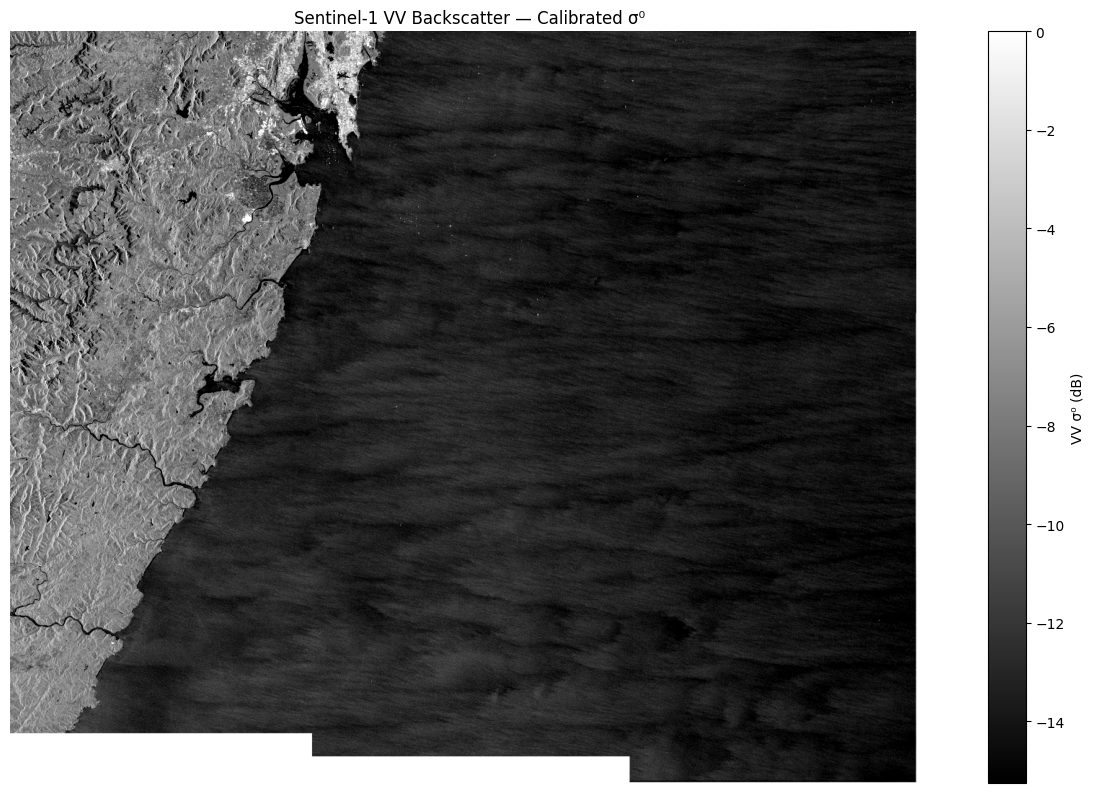

Display range:
2nd percentile: -15.25 dB
98th percentile: 0.0 dB


In [8]:
# MEMORY-SAFE VISUALIZATION OF CALIBRATED VV σ⁰

import rasterio
import matplotlib.pyplot as plt
import numpy as np

with rasterio.open(OUTPUT_SIGMA0) as src:

    # Downsample heavily for visualization
    scale = 20

    display = src.read(
        1,
        out_shape=(
            1,
            src.height // scale,
            src.width // scale
        ),
        resampling=rasterio.enums.Resampling.average
    )

# Remove invalid values
display = np.where(np.isfinite(display), display, np.nan)

# Robust display range
vmin, vmax = np.nanpercentile(display, [2, 98])

plt.figure(figsize=(12, 8))

plt.imshow(
    display,
    cmap="gray",
    vmin=vmin,
    vmax=vmax
)

plt.colorbar(label="VV σ⁰ (dB)")
plt.title("Sentinel-1 VV Backscatter — Calibrated σ⁰")
plt.axis("off")
plt.tight_layout()
plt.show()

print("Display range:")
print("2nd percentile:", round(float(vmin), 2), "dB")
print("98th percentile:", round(float(vmax), 2), "dB")

In [9]:
# QC: Check calibrated Sentinel-1 VV image numerically

import rasterio
import numpy as np

with rasterio.open(OUTPUT_SIGMA0) as src:

    # Read a small representative window from the center
    h, w = src.height, src.width

    window = rasterio.windows.Window(
        col_off=w//2 - 2000,
        row_off=h//2 - 2000,
        width=4000,
        height=4000
    )

    sample = src.read(1, window=window)

sample = sample[np.isfinite(sample)]

print("Number of sampled pixels:", len(sample))
print()
print("Min:", np.min(sample), "dB")
print("1%:", np.percentile(sample, 1), "dB")
print("5%:", np.percentile(sample, 5), "dB")
print("25%:", np.percentile(sample, 25), "dB")
print("50%:", np.percentile(sample, 50), "dB")
print("75%:", np.percentile(sample, 75), "dB")
print("95%:", np.percentile(sample, 95), "dB")
print("99%:", np.percentile(sample, 99), "dB")
print("Max:", np.max(sample), "dB")

Number of sampled pixels: 16000000

Min: -32.12512 dB
1%: -19.199623 dB
5%: -17.141014 dB
25%: -14.499446 dB
50%: -12.817743 dB
75%: -11.2448845 dB
95%: -9.127644 dB
99%: -7.722886 dB
Max: 11.482166 dB


In [11]:
# Inspect Sentinel-1 geolocation information

annotation_files = list(
    S1_SAFE.glob("annotation/s1d-iw-grd-vv-*.xml")
)

print("VV annotation files:", len(annotation_files))

for f in annotation_files:
    print(f)

if not annotation_files:
    raise RuntimeError("VV annotation XML not found.")

VV_ANNOTATION_XML = annotation_files[0]

tree = ET.parse(VV_ANNOTATION_XML)
root = tree.getroot()

# Find geolocation grid points
geo_points = root.findall(".//geolocationGridPoint")

print("\nGeolocation grid points:", len(geo_points))

if geo_points:
    print("\nFirst 5 points:")
    for p in geo_points[:5]:
        print(
            "line:", p.findtext("line"),
            "pixel:", p.findtext("pixel"),
            "lat:", p.findtext("latitude"),
            "lon:", p.findtext("longitude")
        )

VV annotation files: 1
/kaggle/working/sentinel1/extracted/S1D_IW_GRDH_1SDV_20260801T010236_20260801T010307_003925_0071AB_E37D_COG.SAFE/annotation/s1d-iw-grd-vv-20260801t010236-20260801t010307-003925-0071ab-001-cog.xml

Geolocation grid points: 252

First 5 points:
line: 0 pixel: 0 lat: 1.904459816504003e+01 lon: 7.373770419493181e+01
line: 0 pixel: 1276 lat: 1.906648950309915e+01 lon: 7.362085252776615e+01
line: 0 pixel: 2552 lat: 1.908789440402926e+01 lon: 7.350618782871000e+01
line: 0 pixel: 3828 lat: 1.910951095288966e+01 lon: 7.338996693472915e+01
line: 0 pixel: 5104 lat: 1.913161053683514e+01 lon: 7.327070319972171e+01


In [12]:
# Find the Sentinel-1 image region corresponding to our AOI

geo = []

for p in geo_points:
    line = float(p.findtext("line"))
    pixel = float(p.findtext("pixel"))
    lat = float(p.findtext("latitude"))
    lon = float(p.findtext("longitude"))

    geo.append((line, pixel, lat, lon))

geo = np.array(geo)

lines = geo[:, 0]
pixels = geo[:, 1]
lats = geo[:, 2]
lons = geo[:, 3]

# Find geolocation points inside / nearest to AOI
inside = (
    (lons >= AOI["lon_min"]) &
    (lons <= AOI["lon_max"]) &
    (lats >= AOI["lat_min"]) &
    (lats <= AOI["lat_max"])
)

print("Geolocation points inside AOI:", np.sum(inside))

if np.any(inside):
    print("\nImage-coordinate bounds of matching points:")
    print("Line :", lines[inside].min(), "to", lines[inside].max())
    print("Pixel:", pixels[inside].min(), "to", pixels[inside].max())

print("\nFull scene geographic range:")
print("Latitude :", lats.min(), "to", lats.max())
print("Longitude:", lons.min(), "to", lons.max())

Geolocation points inside AOI: 45

Image-coordinate bounds of matching points:
Line : 2008.0 to 14056.0
Pixel: 6380.0 to 17864.0

Full scene geographic range:
Latitude : 17.15915553182095 to 19.47376577987501
Longitude: 70.9990839560215 to 73.73770419493181


In [13]:
# Crop calibrated VV σ⁰ to the approximate AOI region

AOI_CROP = "/kaggle/working/sentinel1/vv_sigma0_aoi.tif"

row_min = int(lines[inside].min())
row_max = int(lines[inside].max())
col_min = int(pixels[inside].min())
col_max = int(pixels[inside].max())

with rasterio.open(OUTPUT_SIGMA0) as src:

    window = rasterio.windows.Window(
        col_off=col_min,
        row_off=row_min,
        width=col_max - col_min + 1,
        height=row_max - row_min + 1
    )

    crop = src.read(1, window=window)

    profile = src.profile.copy()
    profile.update(
        height=crop.shape[0],
        width=crop.shape[1],
        transform=rasterio.windows.transform(window, src.transform),
        compress="deflate"
    )

    with rasterio.open(AOI_CROP, "w", **profile) as dst:
        dst.write(crop, 1)

print("AOI crop saved:")
print(AOI_CROP)
print("Crop shape:", crop.shape)
print("Crop size (MB):", round(os.path.getsize(AOI_CROP) / 1024**2, 2))

AOI crop saved:
/kaggle/working/sentinel1/vv_sigma0_aoi.tif
Crop shape: (12049, 11485)
Crop size (MB): 443.59


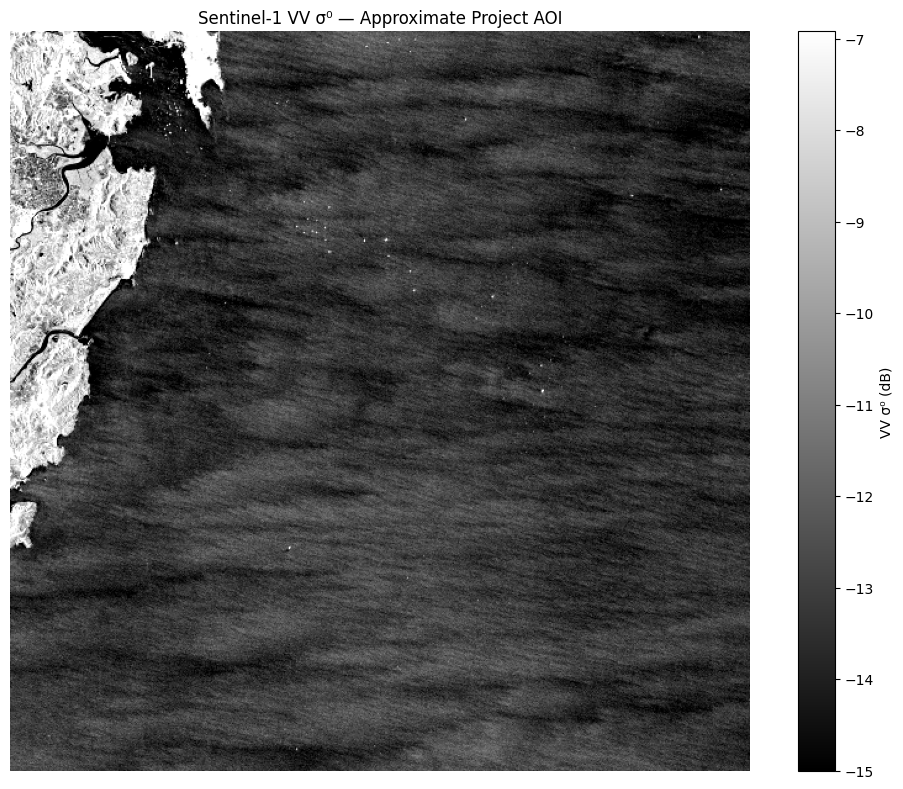

AOI display range:
-15.01 to -6.92 dB


In [14]:
# VISUALIZE THE CALIBRATED AOI CROP

with rasterio.open(AOI_CROP) as src:

    display = src.read(
        1,
        out_shape=(1, 600, 600),
        resampling=rasterio.enums.Resampling.average
    )

display = np.where(np.isfinite(display), display, np.nan)

vmin, vmax = np.nanpercentile(display, [2, 98])

plt.figure(figsize=(10, 8))

plt.imshow(
    display,
    cmap="gray",
    vmin=vmin,
    vmax=vmax
)

plt.colorbar(label="VV σ⁰ (dB)")
plt.title("Sentinel-1 VV σ⁰ — Approximate Project AOI")
plt.axis("off")
plt.tight_layout()
plt.show()

print("AOI display range:")
print(f"{vmin:.2f} to {vmax:.2f} dB")

In [18]:
# REGION SIZE FILTERING
# Determine how many candidate regions survive different minimum sizes.

area_thresholds = [10, 25, 50, 100, 250, 500, 1000]

print("Minimum area → Number of candidate regions\n")

for threshold in area_thresholds:
    count = (regions_df["area_pixels"] >= threshold).sum()
    print(f"{threshold:>5} pixels → {count:>6} regions")

Minimum area → Number of candidate regions

   10 pixels →    432 regions
   25 pixels →    163 regions
   50 pixels →     80 regions
  100 pixels →     44 regions
  250 pixels →     17 regions
  500 pixels →     12 regions
 1000 pixels →      7 regions


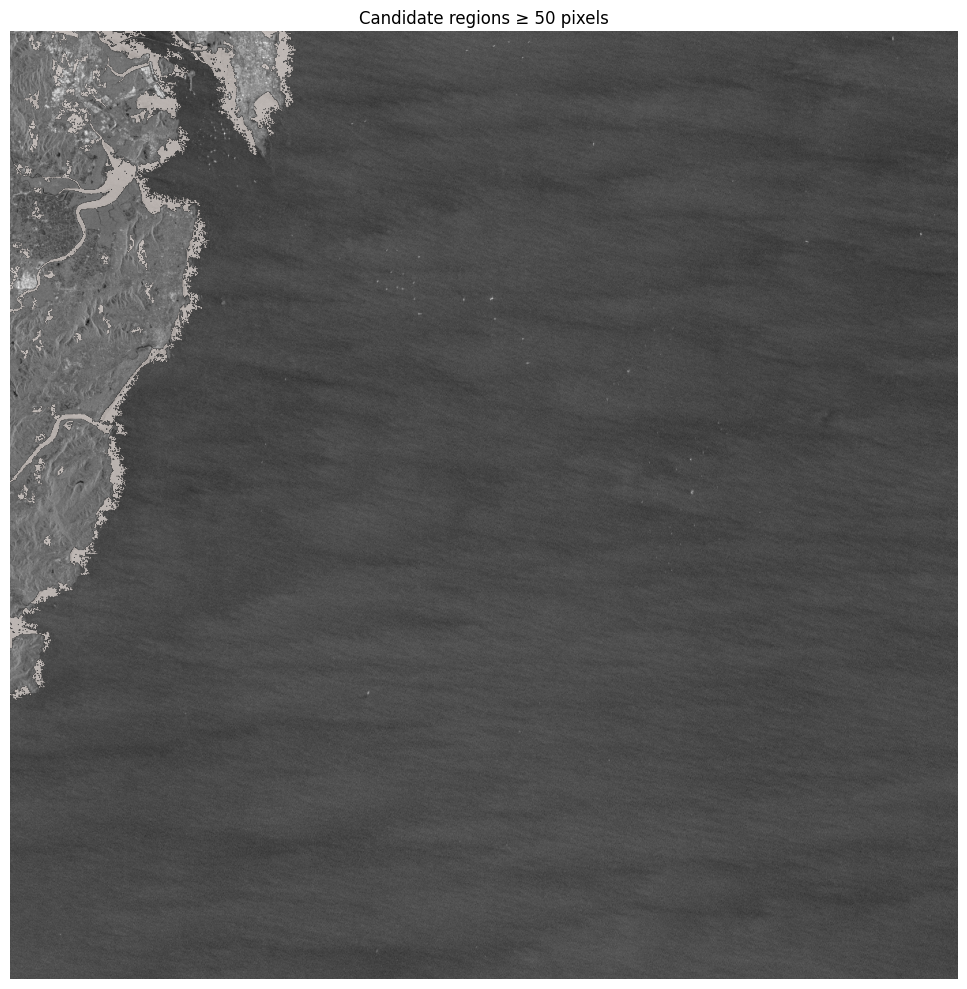

Regions shown: 80


In [19]:
# VISUALIZE LARGER CANDIDATE REGIONS
# Diagnostic only — candidates are NOT oil classifications.

import matplotlib.pyplot as plt
from scipy import ndimage

MIN_AREA = 50

large_ids = regions_df.loc[
    regions_df["area_pixels"] >= MIN_AREA,
    "region_id"
].values

large_mask = np.isin(labeled, large_ids)

plt.figure(figsize=(10, 10))
plt.imshow(img, cmap="gray")
plt.imshow(
    np.ma.masked_where(~large_mask, large_mask),
    cmap="Reds",
    alpha=0.65
)

plt.title(f"Candidate regions ≥ {MIN_AREA} pixels")
plt.axis("off")
plt.show()

print("Regions shown:", len(large_ids))

In [20]:
# CANDIDATE REGION GEOMETRY
# Diagnostic only — still NOT an oil classification.

MIN_AREA = 50

candidate_rows = []

for _, row in regions_df[regions_df["area_pixels"] >= MIN_AREA].iterrows():

    region_id = int(row["region_id"])
    slc = objects[region_id - 1]

    region_mask = (labeled[slc] == region_id)

    # Pixel coordinates within the full 1200x1200 image
    yy, xx = np.where(region_mask)

    y0 = slc[0].start
    x0 = slc[1].start

    cy = yy.mean() + y0
    cx = xx.mean() + x0

    candidate_rows.append({
        "region_id": region_id,
        "area_pixels": int(row["area_pixels"]),
        "height": int(row["height"]),
        "width": int(row["width"]),
        "aspect_ratio": round(row["aspect_ratio"], 2),
        "center_y": round(cy, 1),
        "center_x": round(cx, 1)
    })

candidate_df = pd.DataFrame(candidate_rows)

candidate_df = candidate_df.sort_values(
    "area_pixels",
    ascending=False
)

print("Candidate regions:", len(candidate_df))
print()
print(candidate_df.to_string(index=False))

Candidate regions: 80

 region_id  area_pixels  height  width  aspect_ratio  center_y  center_x
      2545         4483     254    241          1.05     210.8     129.0
       253         2636     145     85          1.71      71.6     274.8
      9978         2291     176    208          1.18     477.0     113.4
         8         1901      66     91          1.38      25.2     152.5
      5549         1496     147     38          3.87     300.0     231.0
        20         1280      97     32          3.03      41.0     346.6
      1811         1051      42     58          1.38      92.0     186.5
     12950          954      81     30          2.70     553.3     134.1
      1896          943      56     40          1.40      99.9     323.0
      2845          718      50     42          1.19     146.5     205.8
     18462          644      42     40          1.05     755.7      12.9
     16353          543      42     35          1.20     665.3      90.5
     14940          441     

In [21]:
# MAP CANDIDATE CENTERS TO APPROXIMATE LAT/LON
# Uses the Sentinel-1 geolocation grid from the original scene.

import xml.etree.ElementTree as ET
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# 1. Read geolocation grid
# ---------------------------------------------------------

tree = ET.parse(VV_ANNOTATION_XML)
root = tree.getroot()

geo_points = []

for gp in root.iter():
    if gp.tag.endswith("geolocationGridPoint"):
        line = pixel = lat = lon = None

        for child in gp:
            tag = child.tag.split("}")[-1]

            if tag == "line":
                line = float(child.text)
            elif tag == "pixel":
                pixel = float(child.text)
            elif tag == "latitude":
                lat = float(child.text)
            elif tag == "longitude":
                lon = float(child.text)

        if None not in (line, pixel, lat, lon):
            geo_points.append((line, pixel, lat, lon))

geo_points = np.array(geo_points)

lines = geo_points[:, 0]
pixels = geo_points[:, 1]
lats = geo_points[:, 2]
lons = geo_points[:, 3]

# ---------------------------------------------------------
# 2. Interpolate geographic coordinates
#    from image coordinates
# ---------------------------------------------------------

from scipy.interpolate import griddata

# Candidate coordinates are in the 1200x1200 downsampled image.
# Convert them back to coordinates in the cropped raster.

CROP_ROW_START = 2008
CROP_COL_START = 6380

CROP_HEIGHT = 12049
CROP_WIDTH = 11485

# Original image coordinates corresponding to candidate centers
candidate_df["orig_line"] = (
    CROP_ROW_START +
    candidate_df["center_y"] * (CROP_HEIGHT / 1200)
)

candidate_df["orig_pixel"] = (
    CROP_COL_START +
    candidate_df["center_x"] * (CROP_WIDTH / 1200)
)

# Interpolate lat/lon from Sentinel-1 geolocation points
candidate_df["latitude"] = griddata(
    (lines, pixels),
    lats,
    (candidate_df["orig_line"], candidate_df["orig_pixel"]),
    method="linear"
)

candidate_df["longitude"] = griddata(
    (lines, pixels),
    lons,
    (candidate_df["orig_line"], candidate_df["orig_pixel"]),
    method="linear"
)

# ---------------------------------------------------------
# 3. Show candidates with geographic coordinates
# ---------------------------------------------------------

cols = [
    "region_id",
    "area_pixels",
    "height",
    "width",
    "aspect_ratio",
    "latitude",
    "longitude"
]

print(candidate_df[cols].head(20).to_string(index=False))

 region_id  area_pixels  height  width  aspect_ratio  latitude  longitude
      2545         4483     254    241          1.05 18.802206  72.962254
       253         2636     145     85          1.71 18.952283  72.857700
      9978         2291     176    208          1.18 18.558522  72.926267
         8         1901      66     91          1.38 18.974241  72.975639
      5549         1496     147     38          3.87 18.738098  72.854963
        20         1280      97     32          3.03 18.991723  72.799320
      1811         1051      42     58          1.38 18.919302  72.932816
     12950          954      81     30          2.70 18.492681  72.894335
      1896          943      56     40          1.40 18.934512  72.809526
      2845          718      50     42          1.19 18.873077  72.905578
     18462          644      42     40          1.05 18.289234  72.964828
     16353          543      42     35          1.20 18.383940  72.912658
     14940          441      39     33

In [22]:
# CANDIDATE PHYSICAL SIZE
# Convert diagnostic-pixel area into approximate square kilometres.

PIXEL_SIZE_X_M = 11485 / 1200
PIXEL_SIZE_Y_M = 12049 / 1200

candidate_df["area_km2"] = (
    candidate_df["area_pixels"]
    * PIXEL_SIZE_X_M
    * PIXEL_SIZE_Y_M
    / 1e6
)

top_candidates = candidate_df.head(20).copy()

cols = [
    "region_id",
    "area_pixels",
    "area_km2",
    "aspect_ratio",
    "latitude",
    "longitude"
]

print(top_candidates[cols].to_string(index=False))

print("\nApproximate diagnostic pixel size:")
print(f"X: {PIXEL_SIZE_X_M:.2f} m")
print(f"Y: {PIXEL_SIZE_Y_M:.2f} m")

 region_id  area_pixels  area_km2  aspect_ratio  latitude  longitude
      2545         4483  0.430812          1.05 18.802206  72.962254
       253         2636  0.253317          1.71 18.952283  72.857700
      9978         2291  0.220163          1.18 18.558522  72.926267
         8         1901  0.182684          1.38 18.974241  72.975639
      5549         1496  0.143764          3.87 18.738098  72.854963
        20         1280  0.123007          3.03 18.991723  72.799320
      1811         1051  0.101000          1.38 18.919302  72.932816
     12950          954  0.091679          2.70 18.492681  72.894335
      1896          943  0.090621          1.40 18.934512  72.809526
      2845          718  0.068999          1.19 18.873077  72.905578
     18462          644  0.061888          1.05 18.289234  72.964828
     16353          543  0.052182          1.20 18.383940  72.912658
     14940          441  0.042380          1.18 18.441858  72.896568
      2530          400  0.038440 

In [23]:
# WIND CONTEXT FOR SAR CANDIDATES
# Interpolate ERA5 10-m wind at each candidate location.

import xarray as xr
import numpy as np

era5 = xr.open_dataset(ERA5_FILE)

print("ERA5 variables:", list(era5.data_vars))

# Detect coordinate names
lat_name = "latitude" if "latitude" in era5.coords else "lat"
lon_name = "longitude" if "longitude" in era5.coords else "lon"
time_name = "valid_time" if "valid_time" in era5.coords else "time"

u10 = era5["u10"]
v10 = era5["v10"]

# Use the SAR acquisition time: 01:02 UTC
sar_time = pd.Timestamp("2026-08-01T01:02:36")

u_candidates = u10.interp(
    {
        lat_name: xr.DataArray(candidate_df["latitude"].values, dims="candidate"),
        lon_name: xr.DataArray(candidate_df["longitude"].values, dims="candidate"),
        time_name: sar_time
    }
).values

v_candidates = v10.interp(
    {
        lat_name: xr.DataArray(candidate_df["latitude"].values, dims="candidate"),
        lon_name: xr.DataArray(candidate_df["longitude"].values, dims="candidate"),
        time_name: sar_time
    }
).values

wind_speed = np.sqrt(u_candidates**2 + v_candidates**2)

candidate_df["u10_ms"] = u_candidates
candidate_df["v10_ms"] = v_candidates
candidate_df["wind_speed_ms"] = wind_speed

cols = [
    "region_id",
    "area_km2",
    "aspect_ratio",
    "latitude",
    "longitude",
    "wind_speed_ms"
]

print(
    candidate_df[cols]
    .head(20)
    .to_string(index=False)
)

ERA5 variables: ['u10', 'v10']
 region_id  area_km2  aspect_ratio  latitude  longitude  wind_speed_ms
      2545  0.430812          1.05 18.802206  72.962254       7.022196
       253  0.253317          1.71 18.952283  72.857700       8.526416
      9978  0.220163          1.18 18.558522  72.926267       7.347754
         8  0.182684          1.38 18.974241  72.975639       6.832331
      5549  0.143764          3.87 18.738098  72.854963       8.588581
        20  0.123007          3.03 18.991723  72.799320       9.367385
      1811  0.101000          1.38 18.919302  72.932816       7.444381
     12950  0.091679          2.70 18.492681  72.894335       7.767486
      1896  0.090621          1.40 18.934512  72.809526       9.231548
      2845  0.068999          1.19 18.873077  72.905578       7.841815
     18462  0.061888          1.05 18.289234  72.964828       6.741875
     16353  0.052182          1.20 18.383940  72.912658       7.508196
     14940  0.042380          1.18 18.441858  

## SIH 26143 — Automated Oil Spill Attribution Pipeline

**Pipeline:**

New Sentinel-1 scene
→ Stage A: Detect + Geolocate
→ Automatically extract spill location + acquisition time
→ Stage B: Backward hindcast
→ Stage C: AIS vessel attribution
→ Dashboard

For the current prototype, Stage A uses a SAR dark-anomaly detector.
The manually defined spill coordinates/time are NOT part of the final pipeline.

In [25]:
# ============================================================
# PIPELINE CONFIGURATION
# ============================================================

from pathlib import Path
from datetime import timedelta
import numpy as np
import pandas as pd
import rasterio

# Existing project directories
WORK_DIR = Path("/kaggle/working")
S1_DIR = WORK_DIR / "sentinel1"
EXTRACT_DIR = S1_DIR / "extracted"

# Existing calibrated Sentinel-1 product
OUTPUT_SIGMA0 = S1_DIR / "vv_sigma0_db.tif"

# Existing environmental datasets
CMEMS_FILE = WORK_DIR / "cmems" / "currents_hourly.nc"
ERA5_FILE = WORK_DIR / "era5_wind_24h.nc"

print("Pipeline configuration loaded.")
print("Sentinel-1:", OUTPUT_SIGMA0)
print("CMEMS:", CMEMS_FILE)
print("ERA5:", ERA5_FILE)

Pipeline configuration loaded.
Sentinel-1: /kaggle/working/sentinel1/vv_sigma0_db.tif
CMEMS: /kaggle/working/cmems/currents_hourly.nc
ERA5: /kaggle/working/era5_wind_24h.nc


## Stage A — Detect + Geolocate

Input:
- Calibrated Sentinel-1 VV backscatter

Output:
- Candidate slick regions
- Candidate latitude/longitude
- Geometric properties
- Sentinel-1 acquisition time

The acquisition time is read automatically from the Sentinel-1 product metadata.
No spill time is manually entered.

In [26]:
# ============================================================
# STAGE A — AUTOMATICALLY EXTRACT SENTINEL-1 ACQUISITION TIME
# ============================================================

import xml.etree.ElementTree as ET

MEASUREMENT_XML = list(
    S1_SAFE.glob("annotation/s1*-vv-*.xml")
)[0]

tree = ET.parse(MEASUREMENT_XML)
root = tree.getroot()

# Search for product start time
start_time = None

for elem in root.iter():
    if elem.tag.endswith("startTime") and elem.text:
        start_time = elem.text
        break

if start_time is None:
    raise RuntimeError("Could not find Sentinel-1 acquisition time.")

S1_ACQUISITION_TIME = pd.Timestamp(start_time)

print("Sentinel-1 acquisition time:")
print(S1_ACQUISITION_TIME)

Sentinel-1 acquisition time:
2026-08-01 01:02:36.478872


In [27]:
# ============================================================
# STAGE A — PROTOTYPE SLICK DETECTION
# ============================================================

from scipy.ndimage import gaussian_filter, label, find_objects

with rasterio.open(AOI_CROP) as src:
    img = src.read(
        1,
        out_shape=(1, 1200, 1200),
        resampling=rasterio.enums.Resampling.average
    ).astype(np.float32)

valid = np.isfinite(img)

# Estimate local SAR background
background = gaussian_filter(
    np.where(valid, img, np.nanmedian(img)),
    sigma=20
)

# Dark anomaly relative to local background
anomaly = img - background

# Prototype threshold
threshold = np.percentile(anomaly[valid], 5)

candidate_mask = (
    valid &
    (anomaly <= threshold)
)

labeled, num_regions = label(candidate_mask)
objects = find_objects(labeled)

print("Candidate regions:", num_regions)
print("Prototype threshold:", threshold)

Candidate regions: 29553
Prototype threshold: -1.6087632


In [28]:
# ============================================================
# STAGE A — CANDIDATE GEOMETRY
# ============================================================

MIN_AREA_PIXELS = 50

candidates = []

for region_id, slc in enumerate(objects, start=1):

    if slc is None:
        continue

    region = labeled[slc] == region_id
    area = int(region.sum())

    if area < MIN_AREA_PIXELS:
        continue

    y0, y1 = slc[0].start, slc[0].stop
    x0, x1 = slc[1].start, slc[1].stop

    height = y1 - y0
    width = x1 - x0

    center_y = (y0 + y1 - 1) / 2
    center_x = (x0 + x1 - 1) / 2

    candidates.append({
        "region_id": region_id,
        "area_pixels": area,
        "height_pixels": height,
        "width_pixels": width,
        "aspect_ratio": width / height if height else np.nan,
        "center_y": center_y,
        "center_x": center_x,
    })

candidate_df = pd.DataFrame(candidates)

candidate_df = candidate_df.sort_values(
    "area_pixels",
    ascending=False
).reset_index(drop=True)

print("Candidate regions retained:", len(candidate_df))
candidate_df.head(10)

Candidate regions retained: 80


,region_id,area_pixels,height_pixels,width_pixels,aspect_ratio,center_y,center_x
0,2545,4483,254,241,0.948819,231.5,120.0
1,253,2636,145,85,0.586207,84.0,270.0
2,9978,2291,176,208,1.181818,482.5,103.5
3,8,1901,66,91,1.378788,32.5,154.0
4,5549,1496,147,38,0.258503,299.0,233.5
5,20,1280,97,32,0.329897,48.0,345.5
6,1811,1051,42,58,1.380952,95.5,187.5
7,12950,954,81,30,0.370370,552.0,134.5
8,1896,943,56,40,0.714286,104.5,324.5
9,2845,718,50,42,0.840000,144.5,206.5


In [29]:
# ============================================================
# STAGE A — AUTOMATIC CANDIDATE GEOLOCATION
# ============================================================

from scipy.interpolate import griddata

# Original AOI crop geometry
CROP_ROW_START = 2008
CROP_COL_START = 6380
CROP_HEIGHT = 12049
CROP_WIDTH = 11485

# Convert 1200x1200 diagnostic coordinates
# back to original Sentinel-1 image coordinates
candidate_df["orig_line"] = (
    CROP_ROW_START +
    candidate_df["center_y"] * (CROP_HEIGHT / 1200)
)

candidate_df["orig_pixel"] = (
    CROP_COL_START +
    candidate_df["center_x"] * (CROP_WIDTH / 1200)
)

# Geolocation grid from Sentinel-1 annotation
geo_points = []

for gp in root.iter():
    if gp.tag.endswith("geolocationGridPoint"):
        values = {}

        for child in gp:
            tag = child.tag.split("}")[-1]
            if tag in ["line", "pixel", "latitude", "longitude"]:
                values[tag] = float(child.text)

        if len(values) == 4:
            geo_points.append(values)

geo_df = pd.DataFrame(geo_points)

candidate_df["latitude"] = griddata(
    (geo_df["pixel"], geo_df["line"]),
    geo_df["latitude"],
    (candidate_df["orig_pixel"], candidate_df["orig_line"]),
    method="linear"
)

candidate_df["longitude"] = griddata(
    (geo_df["pixel"], geo_df["line"]),
    geo_df["longitude"],
    (candidate_df["orig_pixel"], candidate_df["orig_line"]),
    method="linear"
)

print("Geolocation complete.")
candidate_df[
    ["region_id", "area_pixels", "latitude", "longitude"]
].head(10)

Geolocation complete.


,region_id,area_pixels,latitude,longitude
0,2545,4483,18.781987,72.966319
1,253,2636,18.940256,72.859725
2,9978,2291,18.551885,72.934218
3,8,1901,18.967873,72.972944
4,5549,1496,18.739415,72.852917
5,20,1280,18.985181,72.799071
6,1811,1051,18.916295,72.931273
7,12950,954,18.493927,72.894208
8,1896,943,18.930550,72.807454
9,2845,718,18.875005,72.905319


In [30]:
# ============================================================
# STAGE A OUTPUT
# ============================================================

STAGE_A_OUTPUT = WORK_DIR / "stage_a_candidates.csv"

candidate_df.to_csv(STAGE_A_OUTPUT, index=False)

print("Stage A output saved:")
print(STAGE_A_OUTPUT)

Stage A output saved:
/kaggle/working/stage_a_candidates.csv
